# Predicting High-Selling Video Games
### Team Members
### Carlos Olvera, Chris Mathews, Jared Baron Panares, Carlos Galindo

### The Problem trying to solve
### 1. Introduction

Our goal is to predict whether a video game will be a high-selling
title based on information about the game.

### Prediction: High-selling game prediction — Classification

We define a high-selling game as a game that sells at least
1 million copies globally.

Target:
- 1 = High-Selling (≥ 1 million copies)
- 0 = Not High-Selling (< 1 million copies)

We will compare K-Nearest Neighbors and Decision Tree classifiers.

In [1210]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

## Part 1: Initial Data Exploration

In [1211]:
videogame_df = pd.read_csv("VideoGameAnalysis-2024.csv")
videogame_df.head()
original_df = videogame_df.copy()

In [1212]:
# Initial Data Exploration
videogame_df.shape
videogame_df.info()
videogame_df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64016 entries, 0 to 64015
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   img           64016 non-null  object 
 1   title         64016 non-null  object 
 2   console       64016 non-null  object 
 3   genre         64016 non-null  object 
 4   publisher     64016 non-null  object 
 5   developer     63999 non-null  object 
 6   critic_score  6678 non-null   float64
 7   total_sales   18922 non-null  float64
 8   na_sales      12637 non-null  float64
 9   jp_sales      6726 non-null   float64
 10  pal_sales     12824 non-null  float64
 11  other_sales   15128 non-null  float64
 12  release_date  56965 non-null  object 
 13  last_update   17879 non-null  object 
dtypes: float64(6), object(8)
memory usage: 6.8+ MB


,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
count,64016,64016,64016,64016,64016,63999,6678.000000,18922.000000,12637.000000,6726.000000,12824.000000,15128.000000,56965,17879
unique,56177,39798,81,20,3383,8862,NaN,NaN,NaN,NaN,NaN,NaN,7922,1545
top,/games/boxart/default.jpg,Plants vs. Zombies,PC,Misc,Unknown,Unknown,NaN,NaN,NaN,NaN,NaN,NaN,1994-01-01,2018-01-06
freq,7810,17,12617,9304,8842,4435,NaN,NaN,NaN,NaN,NaN,NaN,515,165
mean,NaN,NaN,NaN,NaN,NaN,NaN,7.220440,0.349113,0.264740,0.102281,0.149472,0.043041,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,1.457066,0.807462,0.494787,0.168811,0.392653,0.126643,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,6.400000,0.030000,0.050000,0.020000,0.010000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,7.500000,0.120000,0.120000,0.040000,0.040000,0.010000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,8.300000,0.340000,0.280000,0.120000,0.140000,0.030000,NaN,NaN


In [1213]:
#Examine missing values
missing = pd.DataFrame({
    "Missing Count": videogame_df.isnull().sum(),
    "Missing Percent": videogame_df.isnull().mean() * 100
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
critic_score,57338,89.568233
jp_sales,57290,89.493252
na_sales,51379,80.259623
pal_sales,51192,79.967508
other_sales,48888,76.368408
last_update,46137,72.071045
total_sales,45094,70.441765
release_date,7051,11.014434
developer,17,0.026556
img,0,0.000000


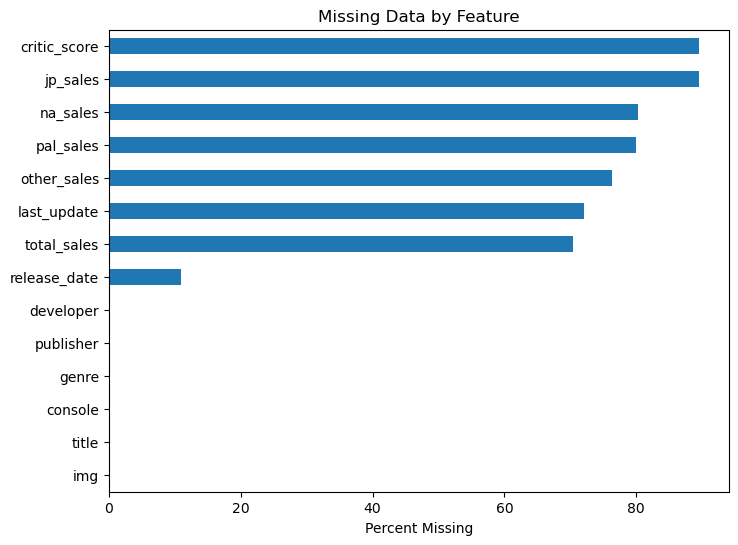

In [1214]:
missing["Missing Percent"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Percent Missing")
plt.title("Missing Data by Feature")
plt.show()

In [1215]:
#inspect category counts
print(f"Genre: {videogame_df['genre'].value_counts().shape[0]}")
print(f"Console: {videogame_df['console'].value_counts().shape[0]}")
print(f"Publisher: {videogame_df['publisher'].nunique()}")
print(f"Developer: {videogame_df['developer'].nunique()}")

Genre: 20
Console: 81
Publisher: 3383
Developer: 8862


# Part 2: Data Cleaning


### Target Variable Creation

We use total_sales to determine whether each historical game was
high-selling. Games with missing total_sales cannot be labeled and
are therefore removed.

After creating the Labels, total_sales is removed from the predictors
to prevent data leakage.

Done so total_sales feature will not dominate prediction

In [1216]:
videogame_df = videogame_df.dropna(subset=["total_sales"])

videogame_df["label_highselling"] = (
    videogame_df["total_sales"] >= 1.0
).astype(int)

In [1217]:
videogame_df["label_highselling"].value_counts()
videogame_df["label_highselling"].value_counts(normalize=True) * 100

label_highselling
0    92.046295
1     7.953705
Name: proportion, dtype: float64

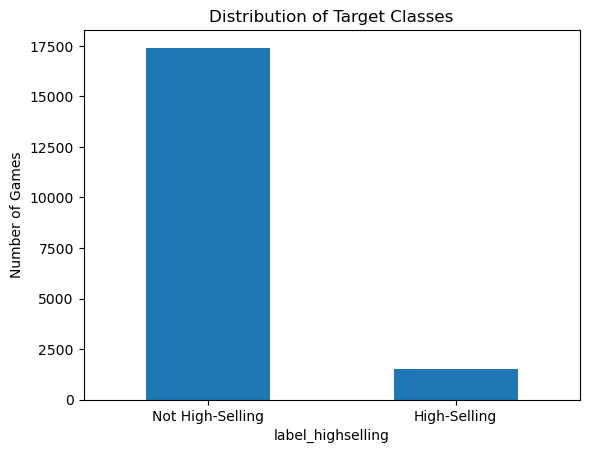

In [1218]:
videogame_df["label_highselling"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xticks([0, 1], ["Not High-Selling", "High-Selling"], rotation=0)
plt.ylabel("Number of Games")
plt.title("Distribution of Target Classes")
plt.show()

The graph because it shows the 92% vs. 8% imbalance

In [1219]:
videogame_df = videogame_df.drop(
    columns=[
        "img",
        "total_sales",
        "na_sales",
        "jp_sales",
        "pal_sales",
        "other_sales"
    ]
)

# game_titles = original_df.loc[videogame_df.index, "title"]


In [1220]:

#Examine missing values after dropping unneeded features
missing = pd.DataFrame({
    "Missing Count": videogame_df.isnull().sum(),
    "Missing Percent": videogame_df.isnull().mean() * 100
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
last_update,14903,78.760173
critic_score,14796,78.194694
release_date,90,0.475637
developer,4,0.021139
title,0,0.000000
console,0,0.000000
genre,0,0.000000
publisher,0,0.000000
label_highselling,0,0.000000


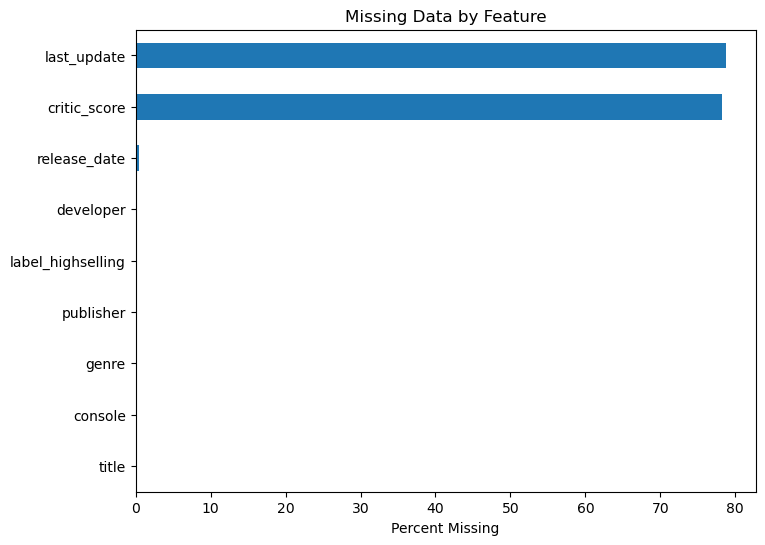

In [1221]:
missing["Missing Percent"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Percent Missing")
plt.title("Missing Data by Feature")
plt.show()

In [1222]:
print(videogame_df.head())

# Feartures to use for modeling
features = [
    "title",
    "console",
    "genre",
    "publisher",
    #"developer",
    "critic_score",
    "release_date",
    "label_highselling"
]

videogame_df = videogame_df[features]

                         title console    genre       publisher  \
0           Grand Theft Auto V     PS3   Action  Rockstar Games   
1           Grand Theft Auto V     PS4   Action  Rockstar Games   
2  Grand Theft Auto: Vice City     PS2   Action  Rockstar Games   
3           Grand Theft Auto V    X360   Action  Rockstar Games   
4    Call of Duty: Black Ops 3     PS4  Shooter      Activision   

        developer  critic_score release_date last_update  label_highselling  
0  Rockstar North           9.4   2013-09-17         NaN                  1  
1  Rockstar North           9.7   2014-11-18  2018-01-03                  1  
2  Rockstar North           9.6   2002-10-28         NaN                  1  
3  Rockstar North           NaN   2013-09-17         NaN                  1  
4        Treyarch           8.1   2015-11-06  2018-01-14                  1  


### Duplicate Records
There were 21 duplicates, we reduced it to 0 so there would not be any unneeded data

In [1223]:
duplicate_count = videogame_df.duplicated().sum()
videogame_df = videogame_df.drop_duplicates()
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 21


In [1224]:
duplicate_count = videogame_df.duplicated().sum()
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


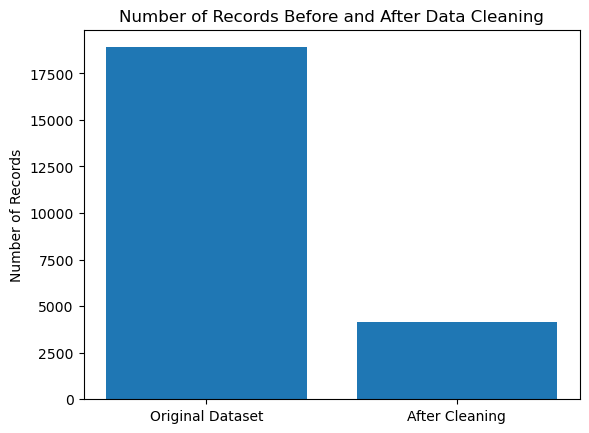

In [1225]:
#The amount of records we are going to use after removing unnecessary columns and dropping rows with missing values
original_records = len(videogame_df)

# Remove any row that has at least one missing value
videogame_df = videogame_df.dropna()

remaining_records = len(videogame_df)

# Compare the number of records before and after data cleaning

plt.bar(
    ["Original Dataset", "After Cleaning"],
    [original_records, remaining_records]
)

plt.title("Number of Records Before and After Data Cleaning")
plt.ylabel("Number of Records")

plt.show()

We have 4123 out of 18901 records that meet our data requirements

## Part 3: Feature Engineering
We want to see if there are any categorical features that we have to one-hot encode

We are going to one-hot encode the categorical features, which are console, genre, and publisher

In [1226]:
categorical_cols = ["console", "genre", "publisher"]

# checking for the number of unique values of these features
print(videogame_df[categorical_cols].nunique())

# console and genre have a lower amount of unique values, so we can just fully one-hot encode

# however, publisher has 213 unique values, so instead we are going to restrict this to 50

# which publishers are in the top 50 most frequent publishers
fifty_top_publishers = (videogame_df["publisher"].value_counts().head(50))

# how many of the 4123 records have these top 50 publishers
publisher_count = videogame_df["publisher"].isin(fifty_top_publishers.index).sum()
total = videogame_df.shape[0]
print(f"Publishers: {publisher_count}/{total} ({publisher_count / total * 100:.2f}%)")

# For the categorical features, this leaves us with
# 28 columns for console
# 20 columns for genre
# 51 columns for publishers (the top 50, plus the 'other' column)



# Replace publishers outside the top 50 with "Other"
videogame_df["publisher"] = videogame_df["publisher"].where(videogame_df["publisher"].isin(fifty_top_publishers.index),"Other")

# One-hot encode categorical features
videogame_df = pd.get_dummies(videogame_df, columns=categorical_cols, dtype=int)

# Check the resulting dimensions
print(videogame_df.shape)

console       28
genre         20
publisher    214
dtype: int64
Publishers: 3622/4123 (87.85%)
(4123, 103)


The remaining features to 'engineer' are the release_date and crtitic_score.

We are going to leave the critic_score as is, since it works as a numerical feature

The release_date will be adjusted to become numerical

In [1227]:
# We want to split the month and year of the release_date feature into two features
# Our reasoning for this is that we believed that release month is dominant feature regarding game sells
# However, we still want to consider the year, in order to have the context of how video games were selling in that point in history

# Convert release_date to datetime
videogame_df["release_date"] = pd.to_datetime(videogame_df["release_date"])

# Extract month and year
videogame_df["release_month"] = videogame_df["release_date"].dt.month
videogame_df["release_year"] = videogame_df["release_date"].dt.year

# Drop the original release_date column
videogame_df = videogame_df.drop(columns=["release_date"])

# Part 4: Algorithm Selection
## First algorithm: Decision Trees.

In [1228]:
# Title must be dropped for training
videogame_labels = videogame_df['label_highselling']
videogame_features = videogame_df.drop(columns=['label_highselling','title'])

# We use the 80-20 split to separate our data into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    videogame_features,
    videogame_labels,
    test_size=0.2,
    random_state=42,
    stratify=videogame_labels
)

# Verify the number of records in each.
print("Number of Training Records: " + str(len(X_train)))
print("Number of Test Records: " + str(len(X_test)))

# We can use the sci-kit learn DecisionTreeClassifier. We can then keep track of its accuracy.
decision_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=10,
    random_state=42
)
decision_tree.fit(X_train, y_train)

prediction = decision_tree.predict(X_test)
accuracy = accuracy_score(y_test, prediction)
print("Accuracy Score: " + str(accuracy))

Number of Training Records: 3298
Number of Test Records: 825
Accuracy Score: 0.8181818181818182


Decision Tress have two hyperparameters that can be tuned to improve accuracy. These are the max depth of the tree (max_depth) and the minimum number of samples required to be at a leaf node (min_samples_leaf). First, we'll adjust the max_depth of the tree to determine the best depth from 1 to 21. We've set that range to make the training plateau easier to observe.

Depth 1- Training Accuracy: 0.8150394178289873
Depth 1- Testing Accuracy: 0.8157575757575758
Depth 2- Training Accuracy: 0.8150394178289873
Depth 2- Testing Accuracy: 0.8157575757575758
Depth 3- Training Accuracy: 0.8150394178289873
Depth 3- Testing Accuracy: 0.8157575757575758
Depth 4- Training Accuracy: 0.8298969072164949
Depth 4- Testing Accuracy: 0.833939393939394
Depth 5- Training Accuracy: 0.8420254699818072
Depth 5- Testing Accuracy: 0.8412121212121212
Depth 6- Training Accuracy: 0.8544572468162522
Depth 6- Testing Accuracy: 0.8290909090909091
Depth 7- Training Accuracy: 0.8596118859915101
Depth 7- Testing Accuracy: 0.8266666666666667
Depth 8- Training Accuracy: 0.8662825955124318
Depth 8- Testing Accuracy: 0.8363636363636363
Depth 9- Training Accuracy: 0.8744693753790176
Depth 9- Testing Accuracy: 0.823030303030303
Depth 10- Training Accuracy: 0.8887204366282595
Depth 10- Testing Accuracy: 0.8181818181818182
Depth 11- Training Accuracy: 0.9005457853244391
Depth 11- Testing Accu

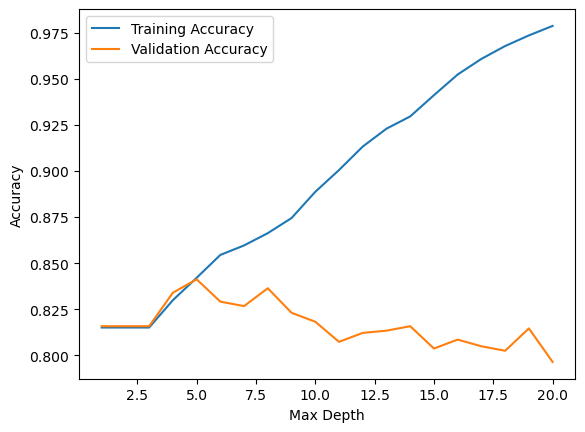

In [1229]:
training_accuracies = []
testing_accuracies = []

for depth in range(1, 21):
    decision_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=depth,
    random_state=42
    )
    decision_tree.fit(X_train, y_train)

    training_prediction = decision_tree.predict(X_train)
    training_accuracy = accuracy_score(y_train, training_prediction)
    training_accuracies.append(training_accuracy)

    testing_prediction = decision_tree.predict(X_test)
    testing_accuracy = accuracy_score(y_test, testing_prediction)
    testing_accuracies.append(testing_accuracy)

    print("Depth " + str(depth) + "- Training Accuracy: " + str(training_accuracy))
    print("Depth " + str(depth) + "- Testing Accuracy: " + str(testing_accuracy))

# We can see a visual of the accuracies here. We want to pick a validation accuracy that's highest
# while the depth is kept low.
plt.plot(range(1, 21), training_accuracies, label='Training Accuracy')
plt.plot(range(1, 21), testing_accuracies, label='Validation Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()

Depth 20- Training Accuracy: 0.8887204366282595
Depth 20- Testing Accuracy: 0.8181818181818182
Depth 20- Training Accuracy: 0.8696179502728927
Depth 20- Testing Accuracy: 0.8290909090909091
Depth 20- Training Accuracy: 0.8623408126137053
Depth 20- Testing Accuracy: 0.816969696969697
Depth 20- Training Accuracy: 0.8590054578532443
Depth 20- Testing Accuracy: 0.8242424242424242
Depth 20- Training Accuracy: 0.8405093996361431
Depth 20- Testing Accuracy: 0.84
Depth 20- Training Accuracy: 0.8362644026682838
Depth 20- Testing Accuracy: 0.8278787878787879


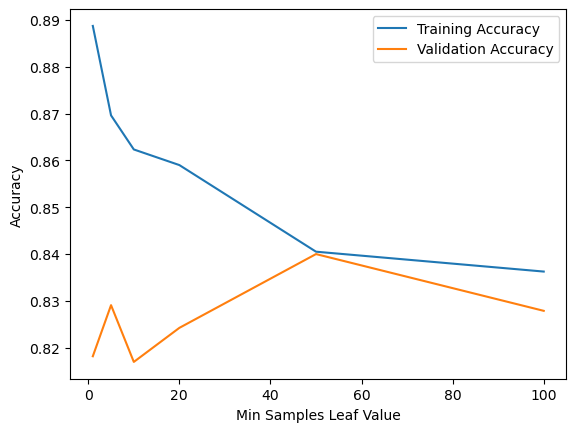

In [1230]:
# We pick a set of leaf values that increases exponentially as smaller hyperparameter values are more 
# are more impactful for this value
min_samples_leaves = [1, 5, 10, 20, 50, 100] 
training_accuracies = []
testing_accuracies = []

for n in min_samples_leaves:
    decision_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=10,
    min_samples_leaf=n,
    random_state=42
    )
    decision_tree.fit(X_train, y_train)

    training_prediction = decision_tree.predict(X_train)
    training_accuracy = accuracy_score(y_train, training_prediction)
    training_accuracies.append(training_accuracy)

    testing_prediction = decision_tree.predict(X_test)
    testing_accuracy = accuracy_score(y_test, testing_prediction)
    testing_accuracies.append(testing_accuracy)

    print("Depth " + str(depth) + "- Training Accuracy: " + str(training_accuracy))
    print("Depth " + str(depth) + "- Testing Accuracy: " + str(testing_accuracy))

# We can see a visual of the accuracies here. We want to pick a validation accuracy that's highest
# while the depth is kept low.
plt.plot(min_samples_leaves, training_accuracies, label='Training Accuracy')
plt.plot(min_samples_leaves, testing_accuracies, label='Validation Accuracy')
plt.xlabel('Min Samples Leaf Value')
plt.ylabel('Accuracy')
plt.legend()

We decided to pick a max_depth of 5 and min_samples_leaf of 50

In [1231]:
# We now evaluate how a decision tree with a maximum depth of 5 and minimum sample leaves of 50 will perform
decision_tree = DecisionTreeClassifier( criterion="entropy", max_depth=5, min_samples_leaf=50, random_state=42)

#we also do cross validation of of the new decision tree to see how it performs with different splits of test and training data
cross = cross_val_score(decision_tree,X_train,y_train,cv=5,scoring="f1")

print("Mean CV F1:", cross.mean())
print("Standard Deviation:", cross.std())

# Determining how the tuned decision tree will perform with new tuned hyperparameters
decision_tree.fit(X_train, y_train)
predictions = decision_tree.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1:", f1_score(y_test, predictions))
cross = cross_val_score(decision_tree, X_train, y_train, cv=5)

print("Mean CV Accuracy: " + str(cross.mean()))
print("Standard Deviation: " + str(cross.std()))

Mean CV F1: 0.3716441627037277
Standard Deviation: 0.04965963325494772
Accuracy: 0.8412121212121212
Precision: 0.6666666666666666
Recall: 0.27631578947368424
F1: 0.39069767441860465
Mean CV Accuracy: 0.8341431001977284
Standard Deviation: 0.005600757117035448


The tuned Decision Tree had high overall accuracy, but its recall, precision, and F1 score were much lower. This means the model is not identifying high-selling games well. Because high-selling games are the minority class in our dataset, we decided to test class weighting.

In [1232]:
# Doing Decision Tree with added class weight balance hyperparameter
balanced_decision_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42
)

balanced_decision_tree.fit(X_train, y_train)

balanced_predictions = balanced_decision_tree.predict(X_test)

print("Accuracy:", accuracy_score(y_test, balanced_predictions))
print("Precision:", precision_score(y_test, balanced_predictions))
print("Recall:", recall_score(y_test, balanced_predictions))
print("F1:", f1_score(y_test, balanced_predictions))

Accuracy: 0.7078787878787879
Precision: 0.3501683501683502
Recall: 0.6842105263157895
F1: 0.46325167037861914


Adding class_weight="balanced caused overall accuracy and precision to decrease, but recall increased majorly from about 0.28 to 0.68. The F1 score also increased from about 0.39 to 0.46. This means the balanced Decision Tree became much better at identifying actual high-selling games, although it also produced more false positive predictions.

In [1233]:
print(confusion_matrix(y_test,balanced_predictions,labels=[1, 0]))
print(classification_report(y_test, balanced_predictions))

[[104  48]
 [193 480]]
              precision    recall  f1-score   support

           0       0.91      0.71      0.80       673
           1       0.35      0.68      0.46       152

    accuracy                           0.71       825
   macro avg       0.63      0.70      0.63       825
weighted avg       0.81      0.71      0.74       825



- correctly found 104 of the 152 actual high-selling games
- missed 48 high-selling games
- incorrectly predicted 193 non-high-selling games as high-selling
- correctly identified 480 non-high-selling games

## Second Algorithm: KNN

Our second classification algorithm is K-Nearest Neighbors. KNN predicts the class of a game by looking at the classes of the most similar games in the training data.

In [1234]:
from sklearn.preprocessing import StandardScaler

# Scalar is needed to help features that with larger values not dominate the distance calculations
scaler = StandardScaler()
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

We first tested a baseline KNN model with k=5. This gives us an initial model that we can compare against after hyperparameter tuning

In [1235]:
# Create the baseline KNN model using 5 nearest neighbors
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model using the standardized training data
knn.fit(scaled_X_train, y_train)

# Predict the classes of the unseen test games
knn_predictions = knn.predict(scaled_X_test)

# Evaluate the baseline model
print("Accuracy:", accuracy_score(y_test, knn_predictions))
print("Precision:", precision_score(y_test, knn_predictions))
print("Recall:", recall_score(y_test, knn_predictions))
print("F1:", f1_score(y_test, knn_predictions))

Accuracy: 0.8472727272727273
Precision: 0.6226415094339622
Recall: 0.4342105263157895
F1: 0.5116279069767442


The baseline KNN achieved strong overall accuracy and precision, but its recall was lower. This means that while many of its high-selling predictions were correct, it still missed a many number of actual high-selling games.



By default, KNN gives every neighbor the same influence on a prediction. We tested both uniform weighting and distance weighting. With distance weighting, closer games have more influence on the prediction than games that are farther away.   
We used 5-fold cross-validation and F1 score to compare the two approaches.

In [1236]:
# Trying both weight types KNN
weight_types = ["uniform", "distance"]
weight_scores = []

# Pipeline ensures that scaling is performed separately inside each cross-validation fold
for w in weight_types:
    knn_pipeline = Pipeline([("scaler", StandardScaler()),("knn", KNeighborsClassifier(n_neighbors=5, weights=w))])

    # Doing Cross validation to see how the different weights perform with different splits of training and testing data
    scores = cross_val_score(knn_pipeline,X_train,y_train,cv=5,scoring="f1")

    weight_scores.append(scores.mean())
    print(w, scores.mean())

uniform 0.4895227463450098
distance 0.5044783094343761


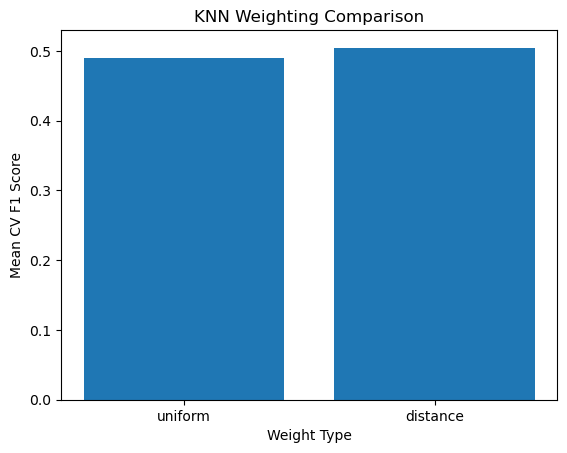

In [1237]:
plt.bar(weight_types, weight_scores)
plt.xlabel("Weight Type")
plt.ylabel("Mean CV F1 Score")
plt.title("KNN Weighting Comparison")
plt.show()

Distance weighting produced a higher mean cross-validation F1 score than uniform weighting. Therefore, we selected distance weighting for further KNN tuning.

After selecting distance weighting, we tested different values of k to determine how many neighboring games should be considered when making a prediction.

We used 5-fold cross-validation with F1 score because our classes are imbalanced and we want to consider both precision and recall when choosing the model.

In [1238]:
# Candidate numbers of neighbors to test
k_values = [3, 5, 7, 9, 11, 15, 21]

# Store the mean cross-validation F1 score for each k
distance_f1_scores = []

for k in k_values:

    # Pipeline ensures that scaling is performed separately inside each cross-validation fold
    knn_pipeline = Pipeline([ ("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k, weights="distance"))])

    # Evaluate each k using 5-fold cross-validation
    scores = cross_val_score(knn_pipeline, X_train,y_train,cv=5,scoring="f1")

    distance_f1_scores.append(scores.mean())

    print("k =", k, "Mean CV F1 =", scores.mean())

k = 3 Mean CV F1 = 0.4882612631803173
k = 5 Mean CV F1 = 0.5044783094343761
k = 7 Mean CV F1 = 0.5009527082387595
k = 9 Mean CV F1 = 0.5032097506688721
k = 11 Mean CV F1 = 0.4934354722630016
k = 15 Mean CV F1 = 0.478893004450715
k = 21 Mean CV F1 = 0.45707046843874577


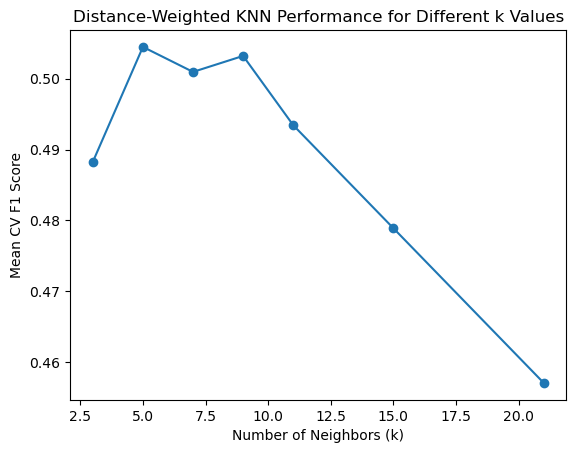

In [1239]:
plt.plot(k_values, distance_f1_scores, marker="o")

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean CV F1 Score")
plt.title("Distance-Weighted KNN Performance for Different k Values")

plt.show()

The highest mean cross-validation F1 score occurred at k=5. Based on our hyperparameter testing, we selected `k=5` and `weights="distance"` for our final KNN model.

In [1240]:
# Final KNN using the hyperparameters selected through cross-validation
final_knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance"
)

# Train using the standardized training data
final_knn.fit(scaled_X_train, y_train)

# Make predictions on the standardized test data
final_knn_predictions = final_knn.predict(scaled_X_test)

# Evaluate final KNN performance
print("Accuracy:", accuracy_score(y_test, final_knn_predictions))
print("Precision:", precision_score(y_test, final_knn_predictions))
print("Recall:", recall_score(y_test, final_knn_predictions))
print("F1:", f1_score(y_test, final_knn_predictions))

Accuracy: 0.8412121212121212
Precision: 0.5867768595041323
Recall: 0.46710526315789475
F1: 0.5201465201465202


After tuning, KNN's accuracy and precision decreased slightly, while recall increased from about 0.43 to 0.47 and F1 increased from about 0.51 to 0.52. This means the tuned model became slightly better at identifying high-selling games while maintaining a better balance between precision and recall.

In [1241]:

# The pipeline standardizes the data first, then applies KNN.
final_knn_pipeline = Pipeline([ ("scaler", StandardScaler()),("knn", KNeighborsClassifier(n_neighbors=5, weights="distance"))])

# Use 5-fold cross-validation on the training data.
final_knn_cv = cross_val_score(
    final_knn_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

# F1 score is used because our classes are imbalanced and want to check consider both precision and recall
print("Mean CV F1:", final_knn_cv.mean())

# Print how much the F1 scores changed between the 5 folds.
print("Standard Deviation:", final_knn_cv.std())

Mean CV F1: 0.5044783094343761
Standard Deviation: 0.041338274927547575


In [1242]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, final_knn_predictions, labels=[1, 0]))
print(classification_report(y_test, final_knn_predictions))

[[ 71  81]
 [ 50 623]]
              precision    recall  f1-score   support

           0       0.88      0.93      0.90       673
           1       0.59      0.47      0.52       152

    accuracy                           0.84       825
   macro avg       0.74      0.70      0.71       825
weighted avg       0.83      0.84      0.83       825



The final KNN model:

- correctly identified 71 of the 152 actual high-selling games
- missed 81 high-selling games
- incorrectly predicted 50 not-high-selling games as high-selling
- correctly identified 623 not-high-selling games

KNN had a recall of about 0.47, meaning it identified approximately 47% of the actual high-selling games. Its precision of about 0.59 means that when KNN predicted a game would be high-selling, it was correct about 59% of the time.

# Part 5: Comparing Decision Tree and KNN

Both models were evaluated using the same test data. Because our dataset contains fewer high-selling games than not-high-selling games, we compare accuracy, precision, recall, and F1 rather than relying only on accuracy.

In [1243]:
# Compare the final Decision Tree and KNN models

# Calculate the final evaluation scores for the balanced Decision Tree
decision_tree_scores = {
    "Accuracy": accuracy_score(y_test, balanced_predictions),
    "Precision": precision_score(y_test, balanced_predictions),
    "Recall": recall_score(y_test, balanced_predictions),
    "F1": f1_score(y_test, balanced_predictions)
}

# Calculate the same evaluation scores for the final tuned KNN model
knn_scores = {
    "Accuracy": accuracy_score(y_test, final_knn_predictions),
    "Precision": precision_score(y_test, final_knn_predictions),
    "Recall": recall_score(y_test, final_knn_predictions),
    "F1": f1_score(y_test, final_knn_predictions)
}

# Put scores into a dataframe, each column represents a model and each row represents an evaluation metric
model_comparison = pd.DataFrame({
    "Decision Tree": decision_tree_scores,
    "KNN": knn_scores
})

model_comparison

,Decision Tree,KNN
Accuracy,0.707879,0.841212
Precision,0.350168,0.586777
Recall,0.684211,0.467105
F1,0.463252,0.520147


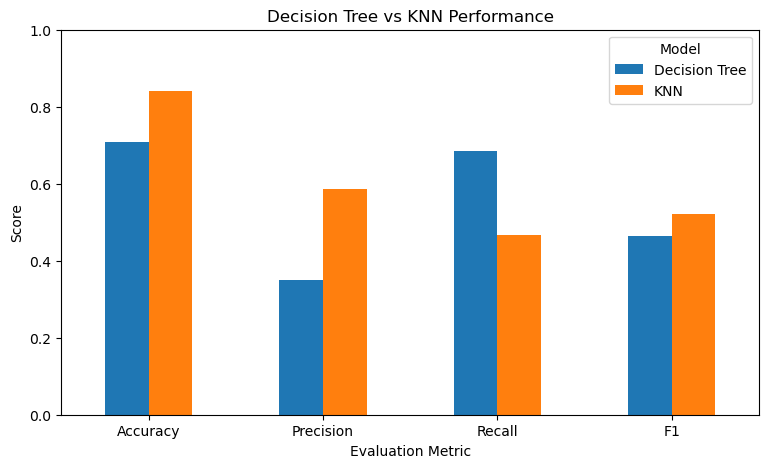

In [1244]:

# Create a bar graph to visually compare the evaluation metrics of the final Decision Tree and KNN models.
model_comparison.plot(kind="bar",figsize=(9, 5))

plt.title("Decision Tree vs KNN Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")

plt.show()

KNN achieved higher accuracy, precision, and F1, while the balanced Decision Tree achieved higher recall. This means KNN provided better overall performance, while the Decision Tree identified a larger percentage of the actual high-selling games.

In [1245]:
print("Decision Tree Confusion Matrix")
print(
    confusion_matrix(
        y_test,
        balanced_predictions,
        labels=[1, 0]
    )
)

print("\nKNN Confusion Matrix")
print(
    confusion_matrix(
        y_test,
        final_knn_predictions,
        labels=[1, 0]
    )
)

Decision Tree Confusion Matrix
[[104  48]
 [193 480]]

KNN Confusion Matrix
[[ 71  81]
 [ 50 623]]


# Part 6: Error Analysis

In [1246]:
# Create a dataframe for error analysis
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test
error_analysis["DecisionTree_Prediction"] = balanced_predictions
error_analysis["KNN_Prediction"] = final_knn_predictions

In [1247]:
# Decision Tree false negatives
dt_false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["DecisionTree_Prediction"] == 0)
]

# KNN false negatives
knn_false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["KNN_Prediction"] == 0)
]

print("Decision Tree False Negatives:", len(dt_false_negatives))
print("KNN False Negatives:", len(knn_false_negatives))

Decision Tree False Negatives: 48
KNN False Negatives: 81


In [1248]:
# Decision Tree false positives
dt_false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["DecisionTree_Prediction"] == 1)
]

# KNN false positives
knn_false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["KNN_Prediction"] == 1)
]

print("Decision Tree False Positives:", len(dt_false_positives))
print("KNN False Positives:", len(knn_false_positives))

Decision Tree False Positives: 193
KNN False Positives: 50


The Decision Tree produced fewer false negatives, meaning it identified more actual high-selling games. However, it produced more false positives. KNN was more conservative when predicting high-selling games, resulting in fewer false positives but more missed high-selling titles

# Part 7: Limitations

# Part 8: Conclusion